# 01 · The synthetic dataset

The Pyomo model computes the minimum total debt an electrification project in Rwanda needs, given how its financing is negotiated. Since it's an optimiser and not a learned model, explainability techniques can't be applied to it directly. Instead, I sample the negotiation parameters, solve Pyomo for each combination and train a surrogate on the results. In this notebook I look at that dataset: how it was generated and what it already shows before any modelling.

## 1. The problem

The project is the rollout of grid and off-grid electricity and e-cooking in Rwanda over 12 years (2023–2034). The utility runs under cost-of-service regulation: every year it is entitled to recover its costs plus a return on its assets (the WACC applied to the regulated asset base). Whatever the tariff doesn't cover, the government tops up with long-term subsidies. Investment needs, demand and operating costs are fixed by the technical study, but how the project is financed is negotiated between several parties.

Given those negotiated terms, the Pyomo model (a mixed-integer linear program) finds the investment schedule and financial plan that **minimises the total debt** the project has to raise. Whenever the yearly cash flow is negative, new debt covers the gap. That minimum total debt is the quantity I want to explain.

The eight negotiation inputs, each controlled by a different party:

| Input | Range | Controlled by |
|---|---|---|
| Debt share (equity is the rest) | 0.30 – 0.90 | Bank / sponsors |
| Cost of debt | 2 % – 15 % | Bank |
| Equity premium over debt | 1 – 15 points | Sponsors |
| Grace period | 0 – 5 years | Bank |
| Amortisation period | 15 – 25 years | Bank |
| Grants share of capex | 0 – 0.50 | DFI |
| Realisation years (years receiving grants) | 1 – 5 | DFI |
| Year-1 tariff (then indexed to 5 % inflation) | 0.08 – 0.25 | Government / regulator |

Because the inputs map to actors, how much each one influences the debt can be read as how much bargaining power that actor has over the final outcome.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from xai_financing_surrogate.data import FEATURE_LABELS, FEATURES, TARGET, load_dataset
from xai_financing_surrogate.plotting import BLUE, MUTED, ORANGE, apply_style

apply_style()
dataset = load_dataset()
print(f"{len(dataset)} samples, {len(FEATURES)} inputs")

6000 samples, 8 inputs


## 2. How the data was generated

The dataset was generated with `scripts/run_01_generate_dataset.py`. Every technical input (capex, demand, opex, the 12-year horizon) stays fixed at the Rwanda case, and only the eight negotiation inputs vary.

Since these inputs are negotiated rather than observed, there's no real distribution to estimate, so each one was sampled uniformly over the plausible range agreed with a supervisor. Uniform is the maximum-entropy choice when only the bounds are known: it adds no assumption beyond them. I deliberately avoided a unimodal distribution centred on typical values. That would put most samples around the usual deals, so the surrogate would learn that region best and the explanations would mostly describe the status quo. What I want to know is how much each actor *could* move the debt if they pushed their parameter anywhere in its negotiable range, and that needs every outcome, typical or extreme, to carry the same weight. How the picture changes for typical negotiations is analysed separately later on.

I used Latin Hypercube Sampling so that every input covers its whole range evenly, and solved Pyomo for 6000 combinations. All of them reached a proven optimum.

Besides the eight inputs and the total debt, each sample stores two kinds of extra columns. The first are generation checks (solver status, the largest share of the big-M bound reached and the solve time), which just confirm the data is valid. The second are the totals of each funding source over the horizon: grants from the DFI, long-term subsidies from the government, the service margin paid by consumers through the tariff, and the equity put in by the sponsors. None of these go into the surrogate. They are outputs of the same optimisation, so feeding them in would leak the answer. I keep them to add context to the explanations later on: an actor can lower the debt by shifting the cost onto someone else, and these totals show who ends up paying. One caveat: total debt is the only quantity the optimiser pins down uniquely, so the other totals are descriptive rather than exact.

## 3. The inputs cover their ranges evenly

Latin Hypercube Sampling should give each input an even coverage of its range, with no gaps and no clusters. The histograms below check it.

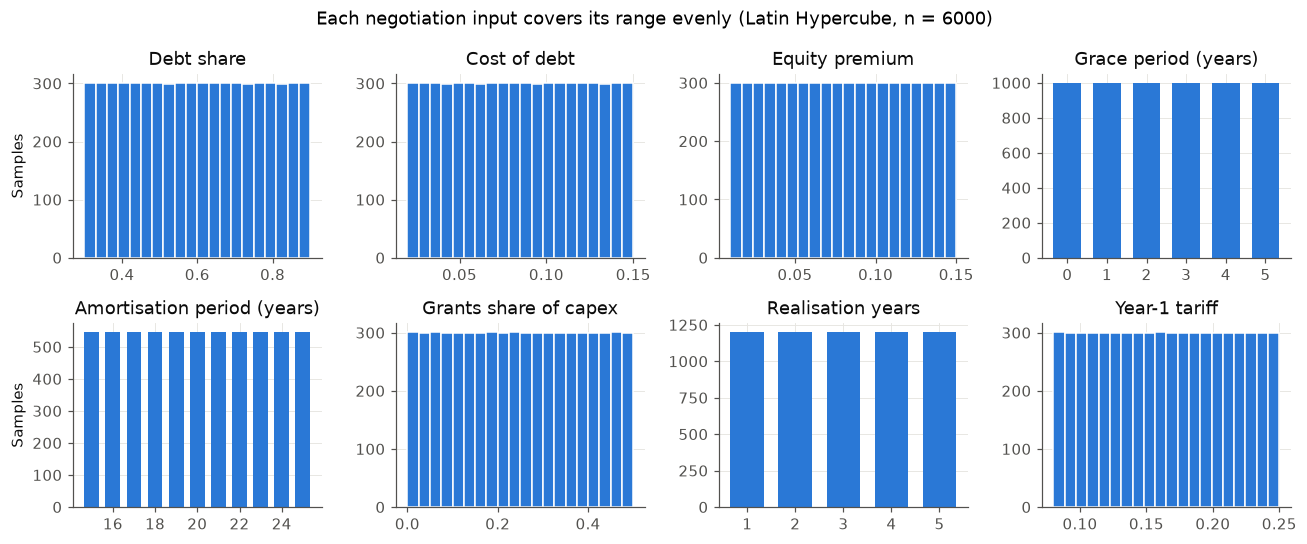

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for ax, feature in zip(axes.flat, FEATURES):
    values = dataset[feature]
    if values.dtype.kind == 'i':
        counts = values.value_counts().sort_index()
        ax.bar(counts.index, counts.values, color=BLUE, width=0.7)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    else:
        ax.hist(values, bins=20, color=BLUE, edgecolor='white', linewidth=1)
    ax.set_title(FEATURE_LABELS[feature])

for ax in axes[:, 0]:
    ax.set_ylabel('Samples')
fig.suptitle('Each negotiation input covers its range evenly (Latin Hypercube, n = 6000)', fontsize=12)
fig.tight_layout()
plt.show()

Every input is spread evenly across its range: the continuous ones show flat histograms, and each whole-year value appears the same number of times (1000 times for each grace period, 1200 for each realisation year). That is exactly what Latin Hypercube Sampling guarantees, and it means the surrogate gets the same amount of evidence everywhere in the negotiation space, extremes included.

## 4. What the total debt looks like

The quantity to explain is the minimum total debt over the 12 years. Before modelling it, it's worth seeing its shape, since it already says a lot about the problem.

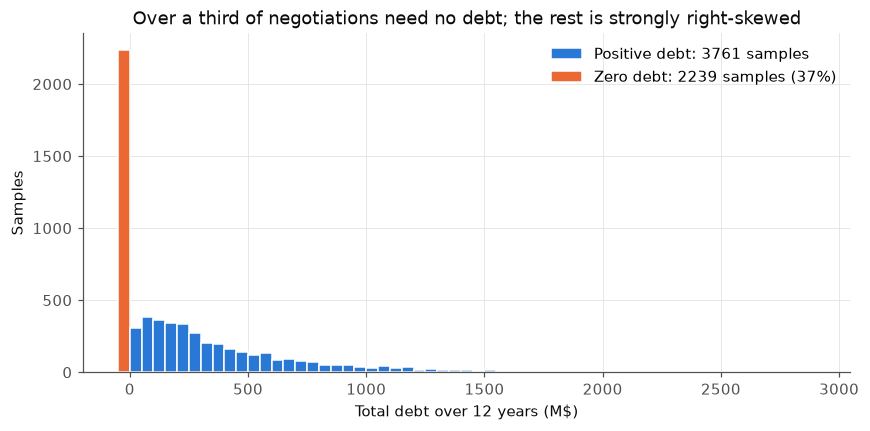

In [ ]:
debt = dataset[TARGET]
zero = debt == 0
bin_width = 50
bins = np.arange(0, debt.max() + bin_width, bin_width)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(-bin_width, zero.sum(), width=bin_width, align='edge', color=ORANGE, edgecolor='white',
       label=f'Zero debt: {zero.sum()} samples ({zero.mean():.0%})')
ax.hist(debt[~zero], bins=bins, color=BLUE, edgecolor='white', linewidth=1,
        label=f'Positive debt: {(~zero).sum()} samples')

ax.set_xlabel('Total debt over 12 years (M$)')
ax.set_ylabel('Samples')
ax.set_title('Over a third of negotiations need no debt; the rest is strongly right-skewed')
ax.legend(frameon=False)
plt.show()

2239 of the 6000 combinations (37%) need no debt at all: under favourable terms the project funds itself. Among the rest, most debts are moderate, but a long tail stretches up to almost 2900 M$, so the mean (248) is more than twice the median (111). This shape matters for the modelling. Whatever surrogate I use has to reproduce a hard floor at zero, which a linear model can't do, and the few very large debts will dominate squared-error metrics like the RMSE. It's also why the train/validation/test split is stratified on zero versus positive debt.

## 5. When does the project need no debt?

A first look at which negotiation conditions lead to zero debt. Since the inputs were sampled independently, comparing their averages between debt-free and indebted samples gives a fair first idea of what drives the project into self-financing, without one input masking another.

In [8]:
comparison = pd.DataFrame({
    'zero debt':     dataset.loc[zero, FEATURES].mean(),
    'positive debt': dataset.loc[~zero, FEATURES].mean(),
})
comparison['difference (%)'] = 100 * (comparison['zero debt'] / comparison['positive debt'] - 1)
comparison.round(3)

,zero debt,positive debt,difference (%)
pct_debt,0.588,0.607,-3.096
cost_debt,0.089,0.082,8.400
equity_premium,0.083,0.078,6.347
grace_period,2.536,2.479,2.314
amortization_period,20.086,19.949,0.686
pct_grants,0.271,0.238,13.779
years_realisation,3.142,2.915,7.772
tariff_y1,0.216,0.135,60.149


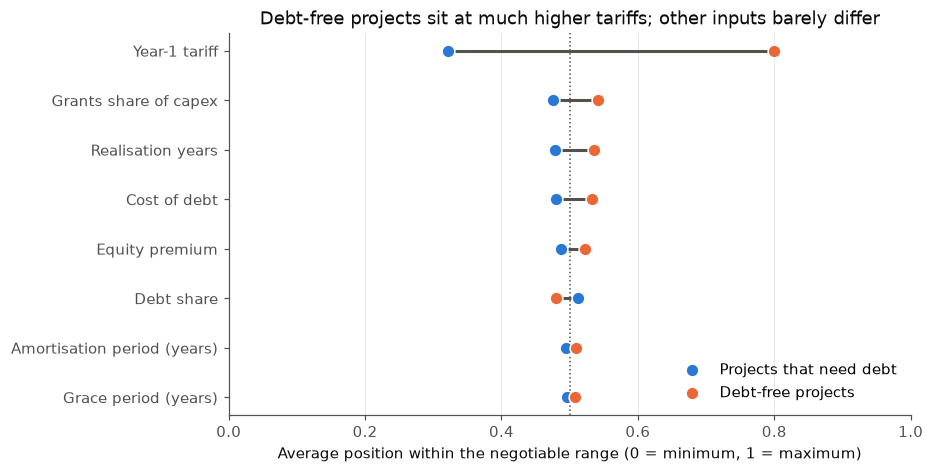

In [10]:
from xai_financing_surrogate.sampling import SPACE_UNIFORM

position = pd.DataFrame(index=FEATURES)
for group in ['zero debt', 'positive debt']:
    for feature in FEATURES:
        low, high = SPACE_UNIFORM[feature].support()
        position.loc[feature, group] = (comparison.loc[feature, group] - low) / (high - low)

gap = (position['zero debt'] - position['positive debt']).abs()
position = position.loc[gap.sort_values().index]
y = np.arange(len(position))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hlines(y, position['positive debt'], position['zero debt'], color=MUTED, linewidth=2)
ax.scatter(position['positive debt'], y, s=70, color=BLUE, edgecolors='white', zorder=3,
           label='Projects that need debt')
ax.scatter(position['zero debt'], y, s=70, color=ORANGE, edgecolors='white', zorder=3,
           label='Debt-free projects')
ax.axvline(0.5, color=MUTED, linestyle=':', linewidth=1)

ax.set_yticks(y, [FEATURE_LABELS[f] for f in position.index])
ax.set_xlim(0, 1)
ax.set_xlabel('Average position within the negotiable range (0 = minimum, 1 = maximum)')
ax.grid(axis='y', visible=False)
ax.legend(frameon=False, loc='lower right')
ax.set_title('Debt-free projects sit at much higher tariffs; other inputs barely differ')
plt.show()

The tariff is in a league of its own. Indebted projects sit on average at about a third of the tariff range, debt-free ones at about 80% of it. This fits the mechanism in the model: once the tariff goes above the cost of service, the difference becomes margin, which is cash the project doesn't have to borrow. Grants and the number of years they arrive over help too, but their gap is far smaller, and the grace and amortisation periods barely move at all.

The surprising part is that debt-free projects also have a slightly *higher* cost of debt and equity premium, when you'd expect expensive capital to push the project into more borrowing, and a slightly lower debt share. My reading of the model is that this comes from two things. Under cost-of-service regulation, the allowed return is the WACC on the asset base, so more expensive capital raises the revenue the project is entitled to. And in the current formulation equity comes in as cash but no dividends ever go out, so a higher equity share or premium works almost like free money. This is a hypothesis about the model rather than about real negotiations, and I check it against Pyomo later. Comparing averages also has a limit: it only shows broad tendencies and can't reveal thresholds or interactions, which is what the explainability methods are for.

## Summary

The dataset covers the whole negotiation space evenly: 6000 combinations of the eight inputs, sampled with a Latin Hypercube over the ranges agreed with the supervisor, all solved to a proven optimum. The total debt has an awkward shape for modelling. Over a third of the combinations need no debt at all, and the rest form a long right tail, so a surrogate has to reproduce a hard floor at zero and will be judged mostly on how it handles the large debts. A first comparison of debt-free and indebted projects points to the tariff as the main driver by far, with grants a distant second, and it also raises a question about the model itself: expensive capital seems to help rather than hurt, probably because equity costs nothing in cash in the current formulation. The next notebook trains the surrogate that the explanations will be built on.